# Exercice 1 : La zone grise du modèle

> **En une phrase :** on cherche les flux sur lesquels l'IDS **hésite**, parce que c'est par là que l'attaquant passera.

**Le scénario.** L'entreprise protège son réseau avec un IDS : une forêt aléatoire (comme au Ch. 1) qui classe chaque flux réseau en « normal » ou « attaque ».
Dans **tous** les exercices de ce chapitre, cet IDS est **la victime**.

**Le plan.**
1. Préparer les données et l'IDS.
2. Regarder la confiance de l'IDS sur chaque flux.
3. Mesurer la zone grise : combien de flux, combien d'erreurs, quelles attaques.
4. Contre-mesure : ne pas décider dans la zone grise.

In [ ]:
# Sur Google Colab seulement : récupère helper.py et les données (en local, cette cellule ne fait rien)
import os, sys
if 'google.colab' in sys.modules and not os.path.exists('helper.py'):
    !git clone -q --depth 1 https://github.com/elyesmanai/8IAR805---Cybersecurity-AI.git /content/cours
    %cd "/content/cours/Chapitre 5 - Sécurité de l'IA"

## Étape 1 : Préparer les données et l'IDS
**Ce qu'on fait :** on charge UNSW-NB15 (du trafic réseau étiqueté) et on entraîne l'IDS. Cette cellule est la même au début de chaque exercice.

In [1]:
from helper import preparer
X_train, y_train, X_test, y_test, types_attaque, ids = preparer()

IDS de l'entreprise -> accuracy = 0.901 | recall (attaques détectées) = 0.864


**👀 Ce qu'on doit voir :** accuracy ≈ 0,90 et recall ≈ 0,86 : l'IDS détecte 86 % des attaques. C'est notre point de départ.

## Étape 2 : La confiance de l'IDS
**Ce qu'on fait :** au lieu de demander « attaque ou normal ? », on demande « **à quel point es-tu sûr ?** » (`predict_proba`).

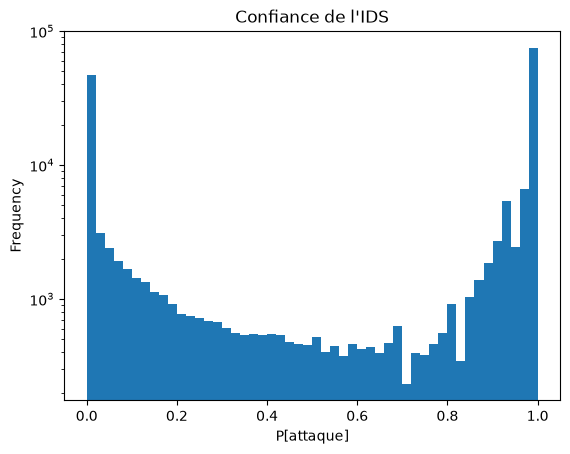

In [2]:
import pandas as pd

confiance = ids.predict_proba(X_test)[:, 1]   # pour chaque flux : P[attaque], entre 0 et 1
pd.Series(confiance).plot(kind='hist', bins=50, logy=True, title="Confiance de l'IDS", xlabel='P[attaque]');

**👀 Ce qu'on doit voir :** deux grands pics, à 0 et à 1 : la plupart du temps, l'IDS est sûr de lui. Entre les deux, un creux : c'est **la zone grise**. *(L'axe vertical est logarithmique : le creux contient quand même des milliers de flux.)*

## Étape 3 : Mesurer la zone grise
**Ce qu'on fait :** on appelle « zone grise » les flux dont la confiance est entre 0,4 et 0,6.

In [3]:
# <-- MODIFIABLE : les bornes de la zone grise (essayez 0.3 et 0.7)
borne_basse, borne_haute = 0.4, 0.6

zone_grise = (confiance > borne_basse) & (confiance < borne_haute)
print(f"{zone_grise.sum()} flux en zone grise, soit {zone_grise.mean():.1%} du trafic")

4423 flux en zone grise, soit 2.5% du trafic


In [4]:
decision = (confiance > 0.5).astype(int)
erreur = decision != y_test

print(f"Erreurs DANS la zone grise : {erreur[zone_grise].mean():.0%}")
print(f"Erreurs HORS zone grise    : {erreur[~zone_grise].mean():.0%}")

Erreurs DANS la zone grise : 53%
Erreurs HORS zone grise    : 9%


**👀 Ce qu'on doit voir :** seulement ≈ 2,5 % du trafic est en zone grise, mais l'IDS s'y trompe **une fois sur deux** (≈ 53 %), contre ≈ 9 % ailleurs.

In [5]:
# Quels types d'attaques tombent dans la zone grise ?
types_attaque[zone_grise & (y_test == 1)].value_counts()

attack_cat
Fuzzers           2186
Exploits           705
DoS                246
Reconnaissance     119
Shellcode          107
Backdoor            41
Generic             36
Analysis            25
Worms                5
Name: count, dtype: int64

**👀 Ce qu'on doit voir :** surtout des **Fuzzers** (≈ 2 200), puis des **Exploits** (≈ 700) : les attaques qui ressemblent le plus à du trafic normal.

**❓ Question pour la classe :** l'API de l'entreprise ne renvoie que « attaque » ou « normal », jamais la confiance. L'attaquant peut-il quand même trouver la zone grise ?

*Piste : en envoyant beaucoup de variantes d'un flux et en regardant où la réponse bascule. C'est le point de départ de l'ex. 2.*

## Étape 4 : Contre-mesure : ne pas décider dans la zone grise
**Ce qu'on fait :** au lieu de décider automatiquement, on envoie les flux de la zone grise à un analyste humain.

In [6]:
print(f"Flux envoyés à un analyste   : {zone_grise.sum()}")
print(f"Erreurs automatiques évitées : {erreur[zone_grise].sum()}")

Flux envoyés à un analyste   : 4423
Erreurs automatiques évitées : 2335


**👀 Ce qu'on doit voir :** ≈ 4 400 flux à vérifier à la main, et ≈ 2 300 erreurs évitées.

**❓ Question pour la classe :** un SOC reçoit 1 million de flux par jour. Avec 2,5 % en zone grise, combien de flux l'analyste doit-il vérifier chaque jour ? Est-ce tenable ?

*Réponse : ≈ 25 000 par jour. Il faut donc resserrer les bornes, ou utiliser une deuxième méthode automatique pour ces cas.*

## Ce qu'il faut retenir
- Un modèle donne une décision **et** une confiance. Quand la confiance est moyenne, il se trompe beaucoup.
- La zone grise est **la porte d'entrée de l'attaquant** : un petit changement suffit à faire basculer la décision.
- S'abstenir dans la zone grise évite des erreurs, mais coûte du temps d'analyste.

**Exercice suivant :** l'attaquant ne voit pas la confiance. Il va donc commencer par **copier** le modèle.